In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline
from sklearn.model_selection import train_test_split
from IPython.display import display
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
from sklearn.metrics import precision_score, recall_score
pd.set_option('display.max_rows', None)
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")

In [3]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
categorical = ['lead_source','industry','employment_status','location']
numerical = ['annual_income','number_of_courses_viewed','interaction_count','lead_score','converted']
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [20]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [6]:
#Question 1
numerical01 = ['lead_score','number_of_courses_viewed','interaction_count','annual_income']
for x in numerical01:
    X_train = df_train[[x]]
    y_train = df_train['converted']
    X_val = df_val[[x]]
    y_val = df_val['converted']
    model = LogisticRegression(solver='liblinear', random_state=1)
    model.fit(X_train, y_train)
    y_pred = model.predict_proba(X_val)[:,1]
    fpr, tpr, thresholds = roc_curve(y_val, y_pred)
    display(round(auc(fpr, tpr),3))

0.783

0.714

0.763

0.613

In [7]:
#Question 2
numerical = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']
train_dict = df_train[categorical + numerical].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
dv.fit(train_dict)
X_train = dv.transform(train_dict)
model = LogisticRegression(solver='liblinear',C=1.0, max_iter=1000)
y_train = df_train['converted']
model.fit(X_train, y_train)
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)
y_val = df_val['converted']
y_pred = model.predict_proba(X_val)[:,1]
fpr, tpr, thresholds = roc_curve(y_val, y_pred)
round(auc(fpr, tpr),3)

0.732

In [8]:
#Question 3 and 4
thresholds = np.round(np.linspace(0, 1, 100),2)
precision = []
recall = []
F1 = []
y_pred = model.predict_proba(X_val)[:,1]
y_val = df_val['converted']

for t in thresholds:
    true_positive = ((y_pred >= t) & (y_val == 1)).sum()
    false_positive = ((y_pred >= t) & (y_val == 0)).sum()
    false_negative = ((y_pred < t) & (y_val == 1)).sum()
    true_negative = ((y_pred < t) & (y_val == 0)).sum()

    precisiont = true_positive / ((true_positive + false_positive) + 0.00000001)
    recallt = true_positive / ((true_positive + false_negative) + 0.00000001)
    F1t = (2*precisiont*recallt) / (precisiont + recallt + 0.00000001)
    precision.append(precisiont)
    recall.append(recallt)
    F1.append(F1t)

In [9]:
dfScores = pd.DataFrame([thresholds,precision,recall,F1]).T
dfScores.columns = ['Thresholds','Precision','Recall','F1']
dfScores.loc[[21,41,61,81]]

,Thresholds,Precision,Recall,F1
21,0.21,0.586000,1.000000,0.738966
41,0.41,0.619048,0.976109,0.757616
61,0.62,0.725914,0.745734,0.735690
81,0.82,0.873016,0.187713,0.308989


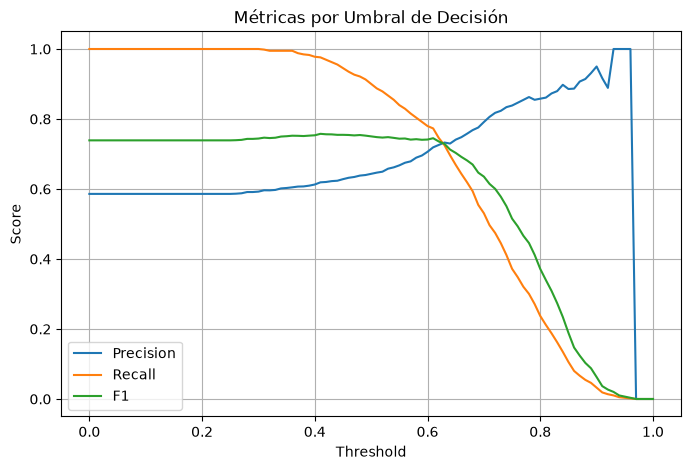

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision, label='Precision')
plt.plot(thresholds, recall, label='Recall')
plt.plot(thresholds, F1, label='F1')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Métricas por Umbral de Decisión')
plt.legend()
plt.grid(True)
plt.show()

In [11]:
#Question 5
def train(df, y, C):
    cat = df[categorical + numerical].to_dict(orient='records')
    
    dv = DictVectorizer(sparse=False)
    dv.fit(cat)

    X = dv.transform(cat)

    model = LogisticRegression(solver='liblinear', max_iter=1000)
    model.fit(X, y)

    return dv, model


def predict(df, dv, model):
    cat = df[categorical + numerical].to_dict(orient='records')
    
    X = dv.transform(cat)

    y_pred = model.predict_proba(X)[:, 1]

    return y_pred



In [12]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [16]:
aucs = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    y_train = df_train['converted'].values

    df_val = df_full_train.iloc[val_idx]
    y_val = df_val['converted'].values

    dv, model = train(df_train, y_train, C=1.0)
    y_pred = predict(df_val, dv, model)

    rocauc = roc_auc_score(y_val, y_pred)
    aucs.append(rocauc)
print('auc = %0.3f ± %0.3f' % (np.mean(aucs), np.std(aucs)))

auc = 0.732 ± 0.007


In [19]:
#Homework05. Save the model
import pickle

output_file = f'model_C={C}.bin'

with open(output_file, 'wb') as f_out:
    pickle.dump((dv, model), f_out)

In [18]:
output_file

'model_C=1.bin'

In [15]:
nfolds = 5
kfold = KFold(n_splits=nfolds, shuffle=True, random_state=1)

for C in [0.000001, 0.001, 1]:
    aucs = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train['converted'].values
        y_val = df_val['converted'].values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)
        
        auc = roc_auc_score(y_val, y_pred)
        aucs.append(auc)

    print('C=%s, auc = %0.3f ± %0.3f' % (C, np.mean(aucs), np.std(aucs)))



C=1e-06, auc = 0.732 ± 0.007
C=0.001, auc = 0.732 ± 0.007
C=1, auc = 0.732 ± 0.007
